# BloodLink – Social Network Analysis

## Geographical Blood Bank Network

**Objective:** To construct and analyse a geographical network of blood banks using location information from the India Blood Bank Directory.

**Network Type:** Undirected, weighted geographical proximity network.

**Tools:** Python, Pandas, NumPy and NetworkX.

## Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

from pathlib import Path

## Step 2 : Load cleaned dataset

In [4]:
BASE_DIR = Path.cwd()

file_path = (
    BASE_DIR
    / "dataset"
    / "cleaned"
    / "blood_banks_cleaned.csv"
)

# Fix the dataset path: the CSV is usually stored in the project root, not inside the notebook folder
file_path = BASE_DIR.parent / "dataset" / "cleaned" / "blood_banks_cleaned.csv"

if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found at: {file_path}")

data = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Total Blood Banks:", len(data))

Dataset loaded successfully!
Total Blood Banks: 2823


## Step 3: Prepare geographical records

In [5]:
# Select records with valid latitude and longitude
location_data = data.dropna(
    subset=["lat", "lon"]
).copy()

# Keep only valid geographical coordinate ranges
location_data = location_data[
    location_data["lat"].between(-90, 90)
    & location_data["lon"].between(-180, 180)
].copy()

# Assign an identifier to each blood bank
location_data = location_data.reset_index(drop=True)

location_data["bank_id"] = [
    f"BB{i+1}" for i in range(len(location_data))
]

print("Total Records:", len(data))
print("Records with Valid Coordinates:", len(location_data))
print("Records Excluded:", len(data) - len(location_data))

display(location_data.head())

Total Records: 2823
Records with Valid Coordinates: 2439
Records Excluded: 384


,state,district,city,name,address,pin,phone,helpline,website,category,components,apheresis,hours,lat,lon,bank_id
0,andaman-and-nicobar-islands,South Andaman,Port Blair,G.B. Pant Hospital Blood bank,"Atlanta Point, Near Cellular Jail, P.O. Aberde...",744104.0,03192 230628,102,NaN,Government,True,False,24x7,11.67544,92.74734,BB1
1,andaman-and-nicobar-islands,South Andaman,Port Blair,I.N.H.S. Dhanvantri,"Ashvini Nagar, Port Blair, Andaman and Nicobar...",744103.0,03192 248759,NaN,NaN,Government,False,False,24x7,11.64969,92.71742,BB2
2,andaman-and-nicobar-islands,South Andaman,Port Blair,Pillar Health Centre Blood Bank,"Lamba Line, P.B. 526, P.O. Junglighat, Opposit...",744104.0,"03192 233193, 03192 233993",03192 233193,NaN,Charity,False,False,24x7,11.65323,92.73071,BB3
3,andhra-pradesh,Anantapur,Anantapur,"Indian Red Cross Society Blood Bank, District ...","Near JNTU Engeneering College, Sarada Nagar, A...",515002.0,08554 246344,NaN,NaN,Charity,True,False,24x7,14.65494,77.60992,BB4
4,andhra-pradesh,Anantapur,Ananthapur,Government General Hospital Blood Bank,"Government General Hospital, Ananthapur",515001.0,08554 275024,NaN,NaN,Government,True,False,24x7,14.67146,77.59668,BB5


## 2. Haversine Distance Calculation

The Haversine formula calculates the geographical distance between two blood banks using their latitude and longitude coordinates.

The distance is measured in kilometres.

In [6]:
def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate the geographical distance between two locations in kilometres.
    """

    earth_radius = 6371.0

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    lat_difference = lat2 - lat1
    lon_difference = lon2 - lon1

    a = (
        np.sin(lat_difference / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(lon_difference / 2) ** 2
    )

    distance = 2 * earth_radius * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )

    return distance

## Step 4 : Test the distance function

In [7]:
sample_distance = haversine_distance(
    location_data.iloc[0]["lat"],
    location_data.iloc[0]["lon"],
    location_data.iloc[1]["lat"],
    location_data.iloc[1]["lon"]
)

print("Distance between two sample blood banks:")
print(round(sample_distance, 2), "km")

Distance between two sample blood banks:
4.34 km


## 3. Geographical Network Construction

In this project, each blood bank is represented as a node.

Two blood banks are connected when the geographical distance between them is within the selected threshold of 10 km.

These connections represent geographical proximity only, not actual partnerships or blood transfers.

## Step 5 : Build the network

In [8]:
# Set the maximum distance for connecting two blood banks
distance_threshold_km = 10

# Create an undirected network
G = nx.Graph()

# Add blood banks as nodes
for _, row in location_data.iterrows():
    G.add_node(
        row["bank_id"],
        name=row["name"],
        state=row["state"],
        district=row["district"],
        latitude=row["lat"],
        longitude=row["lon"]
    )

# Convert coordinates into radians
coordinates = np.radians(
    location_data[["lat", "lon"]].to_numpy()
)

latitudes = coordinates[:, 0]
longitudes = coordinates[:, 1]

earth_radius = 6371.0

# Compare each blood bank with the remaining blood banks
for i in range(len(location_data) - 1):

    lat_difference = latitudes[i + 1:] - latitudes[i]
    lon_difference = longitudes[i + 1:] - longitudes[i]

    a = (
        np.sin(lat_difference / 2) ** 2
        + np.cos(latitudes[i])
        * np.cos(latitudes[i + 1:])
        * np.sin(lon_difference / 2) ** 2
    )

    distances = 2 * earth_radius * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )

    nearby_indices = np.where(
        distances <= distance_threshold_km
    )[0] + i + 1

    for j in nearby_indices:

        distance = distances[j - i - 1]

        bank_1 = location_data.iloc[i]["bank_id"]
        bank_2 = location_data.iloc[j]["bank_id"]

        G.add_edge(
            bank_1,
            bank_2,
            distance_km=float(distance),
            weight=1 / max(float(distance), 0.001)
        )

print("Network created successfully!")
print("Number of Nodes:", G.number_of_nodes())
print("Number of Edges:", G.number_of_edges())
print("Distance Threshold:", distance_threshold_km, "km")

Network created successfully!
Number of Nodes: 2439
Number of Edges: 10248
Distance Threshold: 10 km


## Step 6 : Network summary

In [9]:
print("Network Analysis Summary")
print("------------------------")

print("Total Blood Banks:", G.number_of_nodes())
print("Total Connections:", G.number_of_edges())

if G.number_of_nodes() > 0:
    print(
        "Average Degree:",
        round(sum(dict(G.degree()).values()) / G.number_of_nodes(), 2)
    )

print(
    "Connected Components:",
    nx.number_connected_components(G)
)

Network Analysis Summary
------------------------
Total Blood Banks: 2439
Total Connections: 10248
Average Degree: 8.4
Connected Components: 960


## 4. Degree Centrality

Degree centrality measures how many nearby blood banks are directly connected to a particular blood bank.

A higher value indicates that the blood bank has more nearby blood banks within the selected 10 km distance.

In [10]:
degree_centrality = nx.degree_centrality(G)

degree_results = pd.DataFrame({
    "bank_id": list(degree_centrality.keys()),
    "degree_centrality": list(degree_centrality.values())
})

degree_results = degree_results.merge(
    location_data[["bank_id", "name", "state", "district"]],
    on="bank_id",
    how="left"
)

degree_results = degree_results.sort_values(
    by="degree_centrality",
    ascending=False
)

display(degree_results.head(10))

,bank_id,degree_centrality,name,state,district
2008,BB2009,0.02297,Institute of Preventive Medicine,telangana,Hyderabad
2015,BB2016,0.02297,Gandhi Hospital Blood Bank,telangana,Hyderabad
2003,BB2004,0.02297,Kamineni Health Services Pvt.Ltd. Blood Bank,telangana,Hyderabad
2000,BB2001,0.02297,Lions Club Matadin Goel Blood Bank,telangana,Hyderabad
1999,BB2000,0.02297,Apollo Hospital Enterprises Ltd,telangana,Hyderabad
1275,BB1276,0.02297,Indian Red Cross Society Blood Bank,maharashtra,Nanded
1984,BB1985,0.02297,Aditya Hospital Blood Bank,telangana,Hyderabad
1995,BB1996,0.02297,Share Medical Care (Mediciti Hospital) Blood Bank,telangana,Hyderabad
1982,BB1983,0.02297,Rudhira Voluntary Blood Bank,telangana,Hyderabad
1983,BB1984,0.02297,Satya Nursing Home Blood Bank,telangana,Hyderabad


## Step 7 : Visualize the top 10

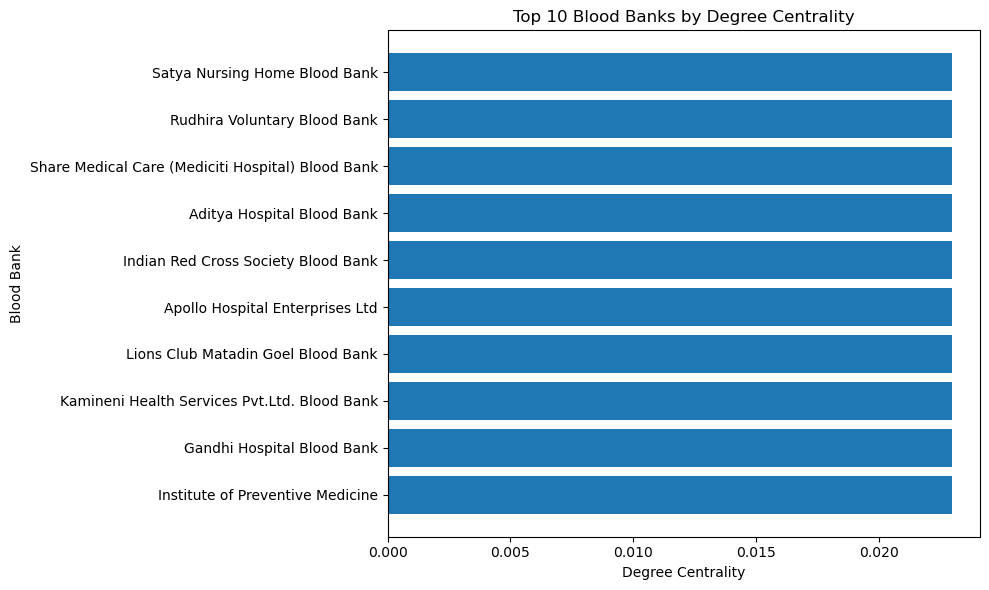

In [11]:
top_banks = degree_results.head(10).sort_values(
    "degree_centrality"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_banks["name"],
    top_banks["degree_centrality"]
)

plt.xlabel("Degree Centrality")
plt.ylabel("Blood Bank")
plt.title("Top 10 Blood Banks by Degree Centrality")
plt.tight_layout()
plt.show()

## 5. Betweenness Centrality

Betweenness centrality identifies nodes that act as bridges between other nodes in a network.

In BloodLink, it helps identify blood banks that may connect different geographical groups of nearby blood banks.

It is calculated using geographical distance as the edge weight.

In [12]:
# Calculate approximate betweenness centrality
betweenness_centrality = nx.betweenness_centrality(
    G,
    k=min(100, G.number_of_nodes()),
    weight="distance_km",
    normalized=True,
    seed=42
)

betweenness_results = pd.DataFrame({
    "bank_id": list(betweenness_centrality.keys()),
    "betweenness_centrality": list(betweenness_centrality.values())
})

betweenness_results = betweenness_results.merge(
    location_data[["bank_id", "name", "state", "district"]],
    on="bank_id",
    how="left"
)

betweenness_results = betweenness_results.sort_values(
    by="betweenness_centrality",
    ascending=False
)

display(betweenness_results.head(10))

,bank_id,betweenness_centrality,name,state,district
1213,BB1214,0.000222,Dr. L. H. Hiranandani Hospital Blood Bank,maharashtra,Mumbai
1237,BB1238,0.000172,Matoshri Valbai Mulji Shah - Arpan Blood Bank,maharashtra,Mumbai
331,BB332,0.000163,Institute of Liver and Biliary Sciences Blood ...,delhi,South West Delhi
292,BB293,0.000143,Mission Jan Jagriti Blood Bank,delhi,North East Delhi
274,BB275,0.000140,Indian Red Cross Society (IRCS) Blood Bank,delhi,Central Delhi
322,BB323,0.000127,Shri Moolchand Khariti-Ram Hospital and Ayurve...,delhi,South Delhi
495,BB496,0.000115,Paras Health Care Private Limited Blood Bank,haryana,Gurgaon
1229,BB1230,0.000107,Kohinoor Hospital Blood Bank,maharashtra,Mumbai
324,BB325,0.000090,Apollo Hospital Blood Bank,delhi,South East Delhi
1227,BB1228,0.000082,K. J. Somaiya Medical College and Hospital Blo...,maharashtra,Mumbai


## 6. Closeness Centrality

Closeness centrality measures how close a node is to other reachable nodes in a network.

In BloodLink, it helps identify blood banks that are geographically well-positioned within their connected network component.

The calculation uses geographical distance in kilometres.

In [13]:
closeness_centrality = nx.closeness_centrality(
    G,
    distance="distance_km"
)

closeness_results = pd.DataFrame({
    "bank_id": list(closeness_centrality.keys()),
    "closeness_centrality": list(closeness_centrality.values())
})

closeness_results = closeness_results.merge(
    location_data[["bank_id", "name", "state", "district"]],
    on="bank_id",
    how="left"
)

closeness_results = closeness_results.sort_values(
    by="closeness_centrality",
    ascending=False
)

display(closeness_results.head(10))

,bank_id,closeness_centrality,name,state,district
2117,BB2118,0.415525,Combined District Hospital Blood Bank,uttar-pradesh,Balrampur
2178,BB2179,0.415525,District Hospital Blood Bank,uttar-pradesh,Gonda
1158,BB1159,0.396613,Shahada Blood Bank (Whole Human Blood),maharashtra,Dhule
1279,BB1280,0.396613,Sahada Blood Bank - Shree Swami Samartha Vaidy...,maharashtra,Nandurbar
834,BB835,0.368877,Malankara Orthodox Syrian Church Medical Missi...,kerala,Ernakulam
986,BB987,0.368877,Malankara Orthodox Syrian Church Medical Missi...,kerala,Thrissur
2320,BB2321,0.278351,B.D. Pandey District Hospital Blood Bank,uttarakhand,Pithoragarh
2319,BB2320,0.278351,B.D. Pandey (P) Hospital Blood Bank,uttarakhand,Pithoragarh
11,BB12,0.071560,District Head Quarters Hospital Blood Bank.,andhra-pradesh,Chittoor
12,BB13,0.071560,Indian Red Cross Society,andhra-pradesh,Chittoor


## 7. Community Detection Using Louvain Algorithm

Community detection identifies groups of closely connected nodes in a network.

In BloodLink, the Louvain algorithm groups blood banks based on geographical proximity.

These communities represent clusters in the constructed network, not actual blood bank partnerships.

## Step 8 : Apply Louvain Algorithm

In [14]:
# Detect communities using the Louvain algorithm
communities = nx.community.louvain_communities(
    G,
    weight="weight",
    seed=42
)

# Assign a community number to each blood bank
community_mapping = {}

for community_id, community in enumerate(communities, start=1):
    for bank_id in community:
        community_mapping[bank_id] = community_id

# Create a results dataframe
community_results = pd.DataFrame({
    "bank_id": list(community_mapping.keys()),
    "community": list(community_mapping.values())
})

community_results = community_results.merge(
    location_data[["bank_id", "name", "state", "district"]],
    on="bank_id",
    how="left"
)

print("Total Communities Detected:", len(communities))
display(community_results.head(10))

Total Communities Detected: 965


,bank_id,community,name,state,district
0,BB3,1,Pillar Health Centre Blood Bank,andaman-and-nicobar-islands,South Andaman
1,BB1,1,G.B. Pant Hospital Blood bank,andaman-and-nicobar-islands,South Andaman
2,BB2,1,I.N.H.S. Dhanvantri,andaman-and-nicobar-islands,South Andaman
3,BB7,2,Rural Development Trust Hospital Blood Bank,andhra-pradesh,Anantapur
4,BB4,2,"Indian Red Cross Society Blood Bank, District ...",andhra-pradesh,Anantapur
5,BB5,2,Government General Hospital Blood Bank,andhra-pradesh,Anantapur
6,BB6,2,Indian Red Cross Society,andhra-pradesh,Anantapur
7,BB8,3,South Central Railway Hospital Blood Bank,andhra-pradesh,Anantapur
8,BB9,4,Indian Red Cross Society Blood Bank,andhra-pradesh,Anantapur
9,BB10,5,Indian Red Cross Society Blood bank RCH -II KA...,andhra-pradesh,Anantapur


## Step 9 : Community Size Analysis

Top 10 Communities by Number of Blood Banks:


community
137    90
499    71
803    67
319    62
715    47
918    42
512    31
875    26
142    25
336    20
Name: count, dtype: int64

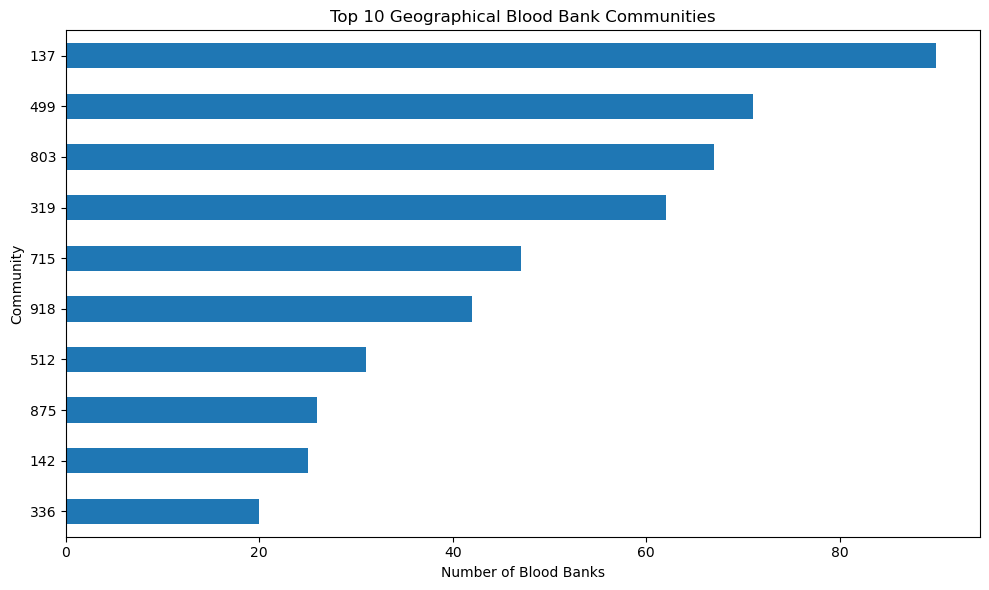

In [15]:
community_sizes = (
    community_results["community"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Top 10 Communities by Number of Blood Banks:")
display(community_sizes.head(10))

plt.figure(figsize=(10, 6))

community_sizes.head(10).sort_values().plot(
    kind="barh"
)

plt.xlabel("Number of Blood Banks")
plt.ylabel("Community")
plt.title("Top 10 Geographical Blood Bank Communities")
plt.tight_layout()
plt.show()

## 8. Geographical Network Visualization

This visualization displays blood banks according to their geographical coordinates.

Different colours represent the communities identified by the Louvain algorithm.

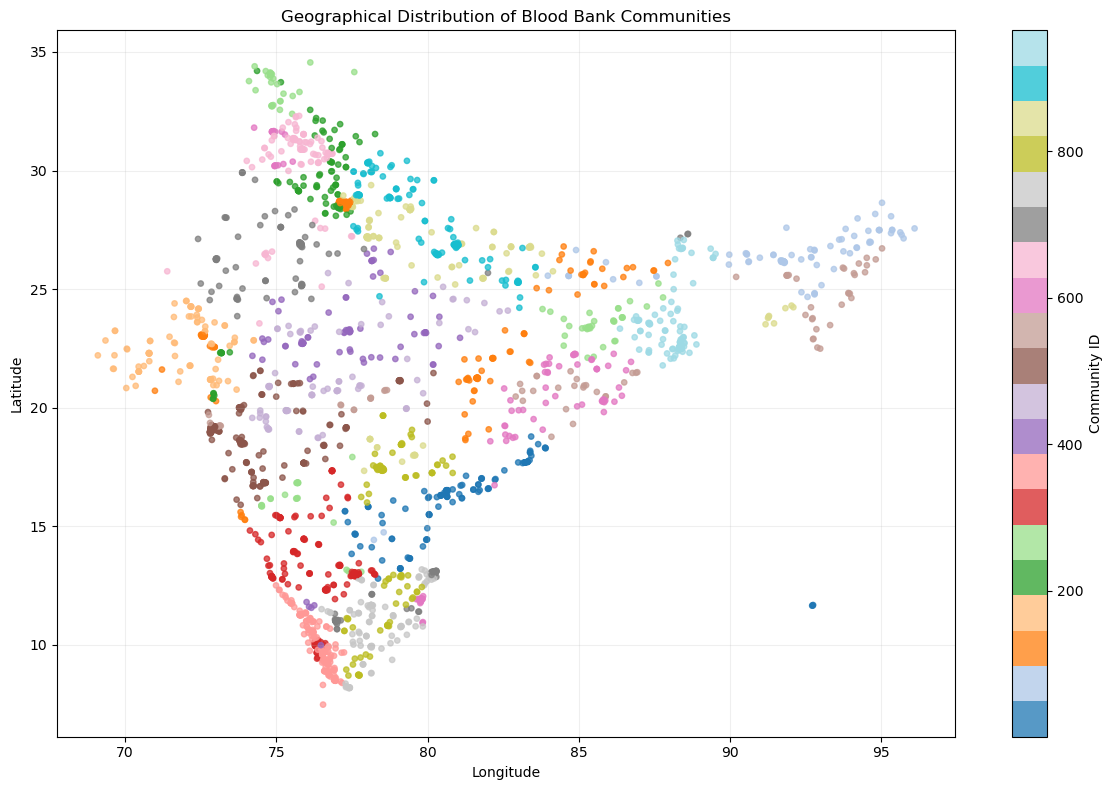

In [16]:
# Combine community information with geographical coordinates
network_visual_data = location_data.merge(
    community_results[["bank_id", "community"]],
    on="bank_id",
    how="left"
)

plt.figure(figsize=(12, 8))

plt.scatter(
    network_visual_data["lon"],
    network_visual_data["lat"],
    c=network_visual_data["community"],
    cmap="tab20",
    s=15,
    alpha=0.75
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Blood Bank Communities")
plt.colorbar(label="Community ID")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Step 10 : Network Analysis Summary

In [17]:
print("BLOODLINK - NETWORK ANALYSIS SUMMARY")
print("=" * 40)

print("Total Blood Banks:", G.number_of_nodes())
print("Total Connections:", G.number_of_edges())

print(
    "Average Degree:",
    round(sum(dict(G.degree()).values()) / G.number_of_nodes(), 2)
)

print(
    "Network Density:",
    round(nx.density(G), 4)
)

print(
    "Connected Components:",
    nx.number_connected_components(G)
)

print("Communities Detected:", len(communities))
print("Distance Threshold:", distance_threshold_km, "km")

BLOODLINK - NETWORK ANALYSIS SUMMARY
Total Blood Banks: 2439
Total Connections: 10248
Average Degree: 8.4
Network Density: 0.0034
Connected Components: 960
Communities Detected: 965
Distance Threshold: 10 km


## 9. Export Network Analysis Results

The network nodes, connections, centrality measures and detected communities are saved as CSV files.

These files will be used in the BloodLink dashboard.

In [18]:
from pathlib import Path

# Create the results folder if it does not exist
results_folder = Path("results")
results_folder.mkdir(parents=True, exist_ok=True)

# Combine all node-level analysis results
network_results = location_data[
    ["bank_id", "name", "state", "district", "lat", "lon"]
].copy()

network_results = network_results.merge(
    degree_results[["bank_id", "degree_centrality"]],
    on="bank_id",
    how="left"
)

network_results = network_results.merge(
    betweenness_results[["bank_id", "betweenness_centrality"]],
    on="bank_id",
    how="left"
)

network_results = network_results.merge(
    closeness_results[["bank_id", "closeness_centrality"]],
    on="bank_id",
    how="left"
)

network_results = network_results.merge(
    community_results[["bank_id", "community"]],
    on="bank_id",
    how="left"
)

# Convert the graph connections into a DataFrame
edge_results = nx.to_pandas_edgelist(G)

# Save the results
network_results.to_csv(
    results_folder / "bloodlink_network_nodes.csv",
    index=False
)

edge_results.to_csv(
    results_folder / "bloodlink_network_edges.csv",
    index=False
)

print("Network analysis results saved successfully!")
print("Files saved:")
print("- results/bloodlink_network_nodes.csv")
print("- results/bloodlink_network_edges.csv")

print("\nNode results:", network_results.shape)
print("Edge results:", edge_results.shape)

Network analysis results saved successfully!
Files saved:
- results/bloodlink_network_nodes.csv
- results/bloodlink_network_edges.csv

Node results: (2439, 10)
Edge results: (10248, 4)
